**1. Importing Libraries**

In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

**2. Loading the Dataset**

In [20]:
df = pd.read_csv('Data/LoanDataset---LoansDatasest.csv')

In [21]:
df.head()

,customer_id,customer_age,customer_income,home_ownership,employment_duration,loan_intent,loan_grade,loan_amnt,loan_int_rate,term_years,historical_default,cred_hist_length,Current_loan_status
0,1.0,22,59000,RENT,123.0,PERSONAL,C,"£35,000.00",16.02,10,Y,3,DEFAULT
1,2.0,21,9600,OWN,5.0,EDUCATION,A,"£1,000.00",11.14,1,NaN,2,NO DEFAULT
2,3.0,25,9600,MORTGAGE,1.0,MEDICAL,B,"£5,500.00",12.87,5,N,3,DEFAULT
3,4.0,23,65500,RENT,4.0,MEDICAL,B,"£35,000.00",15.23,10,N,2,DEFAULT
4,5.0,24,54400,RENT,8.0,MEDICAL,B,"£35,000.00",14.27,10,Y,4,DEFAULT


**3. Handling Missing Values**

In [22]:
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns
df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].mean())

categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

**4. Clean Numeric Columns with Comma Values**

In [23]:
columns_to_clean = ['customer_income', 'loan_amnt']
for col in columns_to_clean:
    df[col] = df[col].replace({',': ''}, regex=True)
    df[col] = pd.to_numeric(df[col], errors='coerce')

**5. Re-check for Any New Missing Numeric Values**

In [24]:
df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].mean())

**6. Encode Categorical Columns to Numeric Labels**

In [25]:
label_encoder = LabelEncoder()

df['home_ownership'] = label_encoder.fit_transform(df['home_ownership'])
df['loan_intent'] = label_encoder.fit_transform(df['loan_intent'])
df['loan_grade'] = label_encoder.fit_transform(df['loan_grade'])
df['historical_default'] = label_encoder.fit_transform(df['historical_default'])
df['Current_loan_status'] = label_encoder.fit_transform(df['Current_loan_status'])

**7. Feature Selection**

In [26]:
X = df.drop(['customer_id', 'Current_loan_status'], axis=1)
y = df['Current_loan_status']

**8. Splitting and Imputing the Data**

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

imputer = SimpleImputer(strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['loan_amnt']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['loan_amnt']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


**9. Model Training with AdaBoost**

In [28]:
model = AdaBoostClassifier(n_estimators=50, random_state=42)
model.fit(X_train, y_train)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


AdaBoostClassifier(random_state=42)

**10. Model Evaluation**

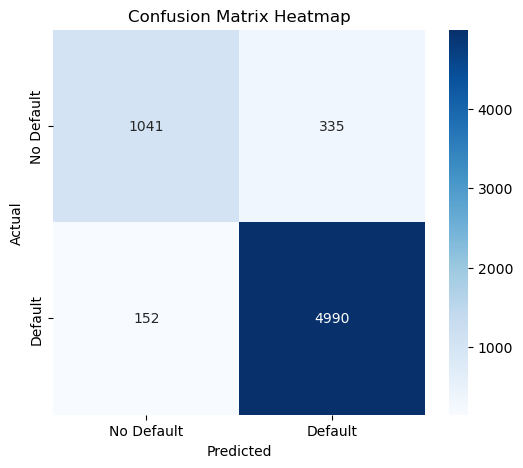

Accuracy:  92.528383%


In [30]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Heatmap')
plt.show()
print(f'Accuracy: {accuracy* 100: 4f}%')